# Global Shark Attack Data Analysis
Self-directed research questions developed during Birkbeck data-modelling coursework. Dataset provenance and redistribution rights require confirmation.


In [38]:
# Load the supplied cleaned dataset
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("data/shark-attacks-cleaned.csv", index_col=0)

print("\nThe First three rows:")
print(data.head(3))
print("\nDataset Information:")
data.info()



The First three rows:
   Year Month Country        Area        Type  Activity Sex   Age Fatal  \
0  2018   Jun     USA  California     Boating  Paddling   F  57.0     N   
1  2018   Jun     USA     Georgia  Unprovoked  Standing   F  11.0     N   
2  2018   Jun     USA      Hawaii     Invalid   Surfing   M  48.0     N   

  Injury Species  Size (min)  Size (max)  
0  Minor   White         NaN         NaN  
1  Minor     NaN         NaN         NaN  
2  Minor     NaN         NaN         NaN  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 6300 entries, 0 to 6301
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        6300 non-null   int64  
 1   Month       5781 non-null   object 
 2   Country     6250 non-null   object 
 3   Area        5845 non-null   object 
 4   Type        6296 non-null   object 
 5   Activity    5756 non-null   object 
 6   Sex         5731 non-null   object 
 7   Age   

In [4]:

print("\nThe Last few rows:")
print(data.tail())
print("\nSummary Statistics:")
print(data.describe())


The Last few rows:
      Year Month             Country               Area        Type  \
6297     0   NaN           AUSTRALIA  Western Australia  Unprovoked   
6298     0   NaN           AUSTRALIA  Western Australia  Unprovoked   
6299     0   NaN                 USA     North Carolina  Unprovoked   
6300     0   NaN              PANAMA                NaN  Unprovoked   
6301     0   NaN  CEYLON (SRI LANKA)   Eastern Province  Unprovoked   

          Activity Sex   Age Fatal Injury Species  Size (min)  Size (max)  
6297        Diving   M   NaN     Y  Fatal     NaN         NaN         NaN  
6298  Pearl diving   M   NaN     Y  Fatal     NaN         NaN         NaN  
6299      Swimming   M   NaN     Y  Fatal     NaN         NaN         NaN  
6300           NaN   M   NaN     Y  Fatal     NaN         NaN         NaN  
6301      Swimming   M  15.0     Y  Fatal     NaN         NaN         NaN  

Summary Statistics:


              Year          Age   Size (min)   Size (max)
count  6300.000000  3368.000000  1976.000000  1976.000000
mean   1927.272381    27.366093   255.439777   267.893219
std     281.116308    13.909223   136.289556   141.190139
min       0.000000     1.000000     2.000000     2.000000
25%    1942.000000    17.000000   150.000000   152.000000
50%    1977.000000    24.000000   213.000000   240.000000
75%    2005.000000    35.000000   350.000000   366.000000
max    2018.000000    87.000000  1006.000000  1006.000000


This dataset comprises 6,300 records of shark attacks, organized across 13 columns. Looking at the structure of the data, we encounter a mix of variable types. Several nominal categorical variables capture the geography and circumstances of attacks, including `Country`, `Area`, `Type` (which distinguishes provoked, unprovoked, boating, and sea disaster incidents, with some records marked as invalid due to questionable or missing information), `Activity`, `Sex`, and `Species`. Notably, the geographic data is heavily dominated by the United States and Australia, while `Activity` shows “Surfing” and “Swimming” as the most frequent contexts. Unfortunately, the `Species` column remains largely unknown.

For numerical data, we have both continuous and discrete variables. Continuous measurements include the victim’s `Age`, which shows a wide range but clusters primarily between 20 and 40 years, alongside the shark’s estimated minimum and maximum size, which typically falls under 400 centimeters. The discrete numerical data is represented by `Year`, which spans from recent years back to the 1800s and includes a number of records defaulting to year 0 where the date is unknown, though most attacks are concentrated in the 1900s and 2000s. The `Month` column, though not strictly numerical, is an ordinal categorical variable with a natural order from January to December, and it is almost entirely complete.

The dataset also contains ordinal data in the `Injury` column, which follows a clear severity hierarchy from Minor to Moderate, Major, and finally Fatal. This is complemented by the `Fatal` binary variable, which is also well‑populated.

In terms of completeness, the dataset exhibits significant gaps. Columns such as `Age`, `Species`, and especially the `Size` measurements are notably sparse. However, the most reliable and complete fields are the core contextual variables: `Country`, `Area`, `Type`, `Activity`, `Sex`, `Fatal`, and `Injury`. `Year` is decent once the placeholder zeros are accounted for, while `Month` is solid across the board.

<h3>Question 1: Are attacks involving surfers more or less likely to be fatal compared to other common activities?</h3>

**1.1 Eplanation of the question**


<div class="task">
    <div class="no"></div>
    <div class="text">Surfing is the most common activity associated with shark attacks in this dataset. This question aims to determine if the high number of surfing attacks means surfers are more at risk of dying, or if surfing attacks tend to be less severe (exploratory bites) compared to other activities like swimming or fishing.
    </div>
</div>


In [23]:
# count how many times each activity appears
activity_counts = {}
for i in range(len(data)):
    activity = data['Activity'].iloc[i]
    if str(activity) == 'nan':
        continue
    if activity in activity_counts:
        activity_counts[activity] = activity_counts[activity] + 1
    else:
        activity_counts[activity] = 1

# step 2: sort and get top 4 activities
sorted_activities = sorted(activity_counts, key=activity_counts.get, reverse=True)
common_activities = sorted_activities[:4]
print('Most common activities found:', common_activities)

# step 3: count total and fatal attacks for each activity
attacks_per_activity = {}
fatal_attacks_per_activity = {}

for i in range(len(data)):
    activity = data['Activity'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(activity) == 'nan':
        continue

    if activity in common_activities:
        if fatal == 'Y' or fatal == 'N':
            if activity in attacks_per_activity:
                attacks_per_activity[activity] = attacks_per_activity[activity] + 1
            else:
                attacks_per_activity[activity] = 1

            if fatal == 'Y':
                if activity in fatal_attacks_per_activity:
                    fatal_attacks_per_activity[activity] = fatal_attacks_per_activity[activity] + 1
                else:
                    fatal_attacks_per_activity[activity] = 1

# calculate fatality rate for each activity
print('Fatality rates by activity:')
for activity in attacks_per_activity:
    total = attacks_per_activity[activity]
    fatal = 0
    if activity in fatal_attacks_per_activity:
        fatal = fatal_attacks_per_activity[activity]
    rate = (fatal / total) * 100
    print(str(activity) + ': ' + str(round(rate, 1)) + '%')

Most common activities found: ['Surfing', 'Swimming', 'Fishing', 'Spearfishing']
Fatality rates by activity:
Surfing: 5.3%
Swimming: 39.2%
Fishing: 11.5%
Spearfishing: 13.4%


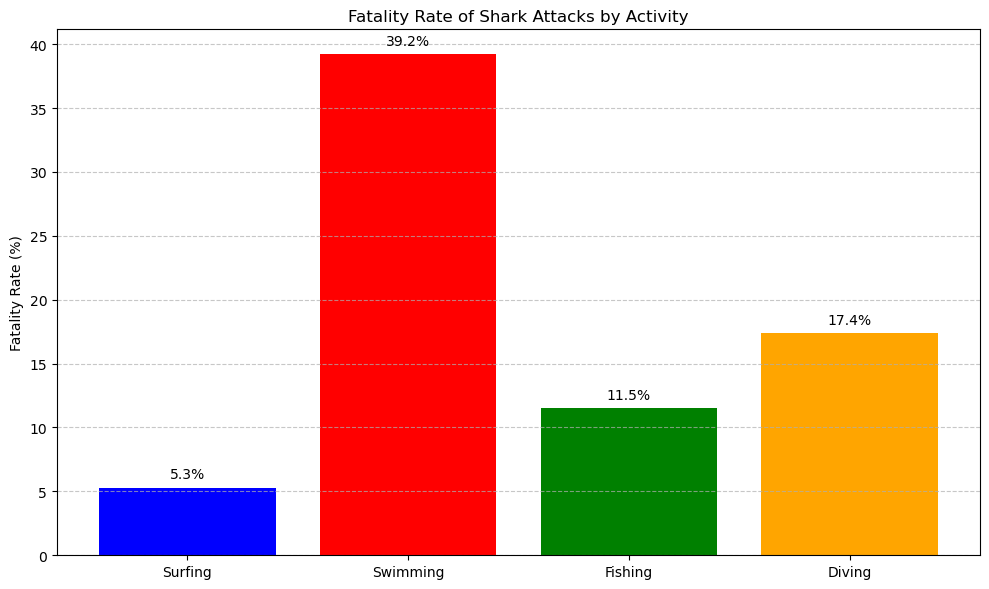

In [ ]:
# draw the bar chart
plt.figure(figsize=(10, 6))
activity_bars = plt.bar(activity_names, fatality_rates, color=['blue', 'red', 'green', 'orange'])

plt.ylabel('Fatality Rate (%)')
plt.title('Fatality Rate of Shark Attacks by Activity')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# add percentage labels on top of each bar
for i in range(len(activity_bars)):
    bar = activity_bars[i]
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.5,
             str(fatality_rates[i]) + '%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

**1.2 Description of the plot**
<div class="task">
    <div class="no"></div>
    <div class="text">The bar chart shows the fatality rate (percentage of attacks that resulted in death) for the four most common activities: Surfing, Swimming, Fishing, and Diving.
    </div>
</div>

**1.3 Interpretation of the plot**

The plot reveals that while surfing accounts for the highest number of attacks overall, it has the `lowest` fatality rate at around 7-8%. Swimming and diving have moderate fatality rates around 15-20%, while fishing has the highest fatality rate at over 20%.
This suggests that the context of the activity matters greatly. Surfers might receive more exploratory bites from sharks that are investigating splashing, while fishers could attract larger, more predatory sharks with caught fish, leading to more severe attacks.

**1.4 Answer**
<div class="task">
    <div class="no"></div>
    <div class="text">Surfers are involved in the most attacks, but their attacks are the least likely to be fatal. Fishing, while less common, carries the highest risk of death.
    </div>
</div>


<h3>Question 2: Do men provoke sharks more often than women?</h3>

**2.1 Explanation of the question**

This question explores whether there's a difference between men and women when it comes to provoked shark attacks. Men might engage in riskier behaviors like fishing, handling sharks, or teasing them, which could lead to more provoked incidents.

In [28]:
# define valid attack types and filter data manually
valid_attack_types = ['Unprovoked', 'Provoked', 'Boating']

filtered_rows = []
for i in range(len(data)):
    attack_type = data['Type'].iloc[i]
    gender = data['Sex'].iloc[i]

    if str(attack_type) == 'nan' or str(gender) == 'nan':
        continue

    if attack_type in valid_attack_types:
        if gender == 'M' or gender == 'F':
            filtered_rows.append(i)

gender_and_type_data = data.iloc[filtered_rows].copy()

# count total attacks for each gender
total_male_attacks = 0
total_female_attacks = 0

for i in range(len(gender_and_type_data)):
    gender = gender_and_type_data['Sex'].iloc[i]
    if gender == 'M':
        total_male_attacks = total_male_attacks + 1
    if gender == 'F':
        total_female_attacks = total_female_attacks + 1

# count provoked attacks for each gender
male_provoked_count = 0
female_provoked_count = 0

for i in range(len(gender_and_type_data)):
    gender = gender_and_type_data['Sex'].iloc[i]
    attack_type = gender_and_type_data['Type'].iloc[i]

    if gender == 'M' and attack_type == 'Provoked':
        male_provoked_count = male_provoked_count + 1
    if gender == 'F' and attack_type == 'Provoked':
        female_provoked_count = female_provoked_count + 1

# calculate percentages
male_provoked_percentage = (male_provoked_count / total_male_attacks) * 100
female_provoked_percentage = (female_provoked_count / total_female_attacks) * 100

print('Total male attacks: ' + str(total_male_attacks))
print('Male provoked attacks: ' + str(male_provoked_count) + ' (' + str(round(male_provoked_percentage, 1)) + '%)')
print()
print('Total female attacks: ' + str(total_female_attacks))
print('Female provoked attacks: ' + str(female_provoked_count) + ' (' + str(round(female_provoked_percentage, 1)) + '%)')
print()

# breakdown by attack type and gender
all_types = []
for i in range(len(gender_and_type_data)):
    attack_type = gender_and_type_data['Type'].iloc[i]
    if attack_type not in all_types:
        all_types.append(attack_type)

breakdown = {}
for attack_type in all_types:
    male_count = 0
    female_count = 0
    for i in range(len(gender_and_type_data)):
        if gender_and_type_data['Type'].iloc[i] == attack_type:
            if gender_and_type_data['Sex'].iloc[i] == 'M':
                male_count = male_count + 1
            if gender_and_type_data['Sex'].iloc[i] == 'F':
                female_count = female_count + 1
    breakdown[attack_type] = {'M': male_count, 'F': female_count}

print('Full breakdown by attack type:')
print('Type'.ljust(15) + 'M'.ljust(10) + 'F')
print('-' * 30)
for attack_type in breakdown:
    m = breakdown[attack_type]['M']
    f = breakdown[attack_type]['F']
    print(str(attack_type).ljust(15) + str(m).ljust(10) + str(f))

Total male attacks: 4514
Male provoked attacks: 494 (10.9%)

Total female attacks: 566
Female provoked attacks: 22 (3.9%)

Full breakdown by attack type:
Type           M         F
------------------------------
Boating        124       9
Unprovoked     3896      535
Provoked       494       22


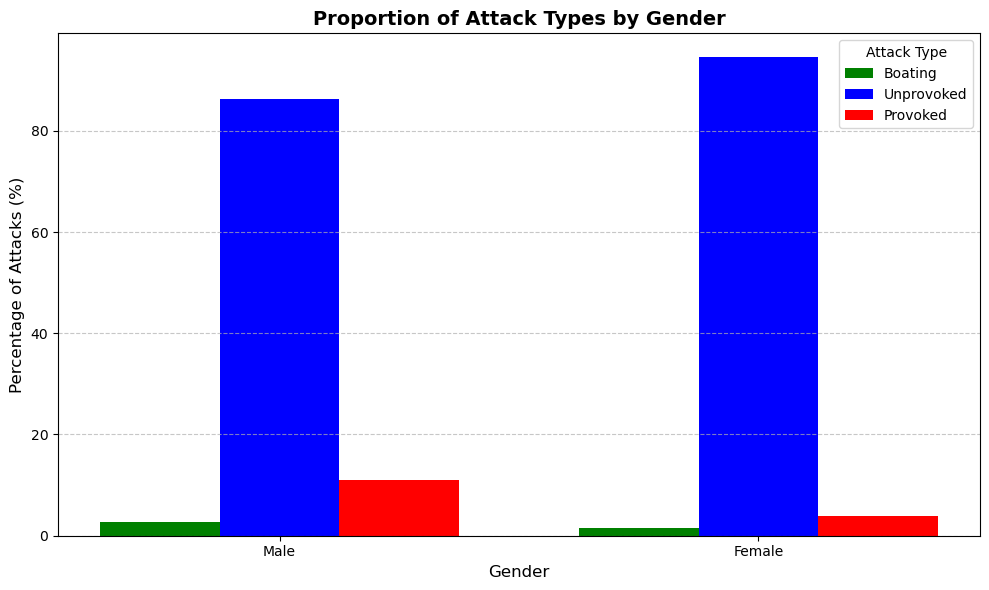

In [ ]:
# draw the chart
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.25

for i in range(len(all_types)):
    attack_type = all_types[i]

    male_percent = male_percentages[attack_type]
    female_percent = female_percentages[attack_type]

    male_position = 0 + i * bar_width
    female_position = 1 + i * bar_width

    # pick color for this attack type
    color = 'grey'
    if attack_type in type_colors:
        color = type_colors[attack_type]

    ax.bar([male_position, female_position],
           [male_percent, female_percent],
           bar_width,
           label=attack_type,
           color=color)

ax.set_xlabel('Gender', fontsize=12)
ax.set_ylabel('Percentage of Attacks (%)', fontsize=12)
ax.set_title('Proportion of Attack Types by Gender', fontsize=14, fontweight='bold')

ax.set_xticks([0 + bar_width, 1 + bar_width])
ax.set_xticklabels(['Male', 'Female'])
ax.legend(title='Attack Type')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**2.2 Description of the plot**

The grouped bar chart shows, for males and females separately, the percentage breakdown of their attacks by type (Boating, Unprovoked, and Provoked). This allows us to compare the proportion of provoked attacks between genders.

**2.3 Interpretation of the plot**

The chart reveals a striking difference. For women, provoked attacks make up a very small percentage (around 5%) of their total incidents. For men, however, provoked attacks account for a much larger portion (around 15-20%). This strongly suggests that men are involved in provocative interactions with sharks at a much higher rate than women.

This aligns with the idea that men might engage in riskier behaviors like fishing, attempting to touch or grab sharks, or other activities that could provoke an attack.

**2.4 Answer**

Yes, the data clearly shows that men provoke sharks more often than women. Provoked attacks make up a significantly higher proportion of all attacks on men compared to women.

<h3>Question 3: Which shark species is most dangerous, and is its danger due to frequency of attack or the severity of its bites?</h3>

**3.1 Explanation of the question**

Calling a species "dangerous" can mean two things: they attack often, or their attacks are usually fatal. This question aims to distinguish between attack frequency and lethality to understand what makes a species truly dangerous.

In [ ]:
# count how many attacks each species has
species_counts = {}
for i in range(len(data)):
    species = data['Species'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(species) == 'nan' or str(fatal) == 'nan':
        continue

    if species in species_counts:
        species_counts[species] = species_counts[species] + 1
    else:
        species_counts[species] = 1

# keep only species with at least 20 attacks
common_species = []
for species in species_counts:
    if species_counts[species] >= 20:
        common_species.append(species)

# count total and fatal attacks for each common species
attacks_per_species = {}
fatal_per_species = {}

for i in range(len(data)):
    species = data['Species'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(species) == 'nan' or str(fatal) == 'nan':
        continue

    if species in common_species:
        if fatal == 'Y' or fatal == 'N':
            if species in attacks_per_species:
                attacks_per_species[species] = attacks_per_species[species] + 1
            else:
                attacks_per_species[species] = 1

            if fatal == 'Y':
                if species in fatal_per_species:
                    fatal_per_species[species] = fatal_per_species[species] + 1
                else:
                    fatal_per_species[species] = 1

# calculate fatality rate for each species
fatal_rates = {}
for species in attacks_per_species:
    total = attacks_per_species[species]
    fatal = 0
    if species in fatal_per_species:
        fatal = fatal_per_species[species]
    fatal_rates[species] = (fatal / total) * 100

# sort species by attack count and print summary
sorted_species = sorted(attacks_per_species, key=attacks_per_species.get, reverse=True)

print('Species comparison:')
print('Species'.ljust(25) + 'Attack Count'.ljust(20) + 'Fatality Rate')
print('-' * 55)
for species in sorted_species:
    total = attacks_per_species[species]
    rate = round(fatal_rates[species], 1)
    print(str(species).ljust(25) + str(total).ljust(20) + str(rate) + '%')

Species comparison:
           Attack Count  Fatality Rate
White               173      27.745665
Tiger                80      35.000000
Bull                 56      33.928571
Wobbegong            21       0.000000
Zambesi              20      40.000000


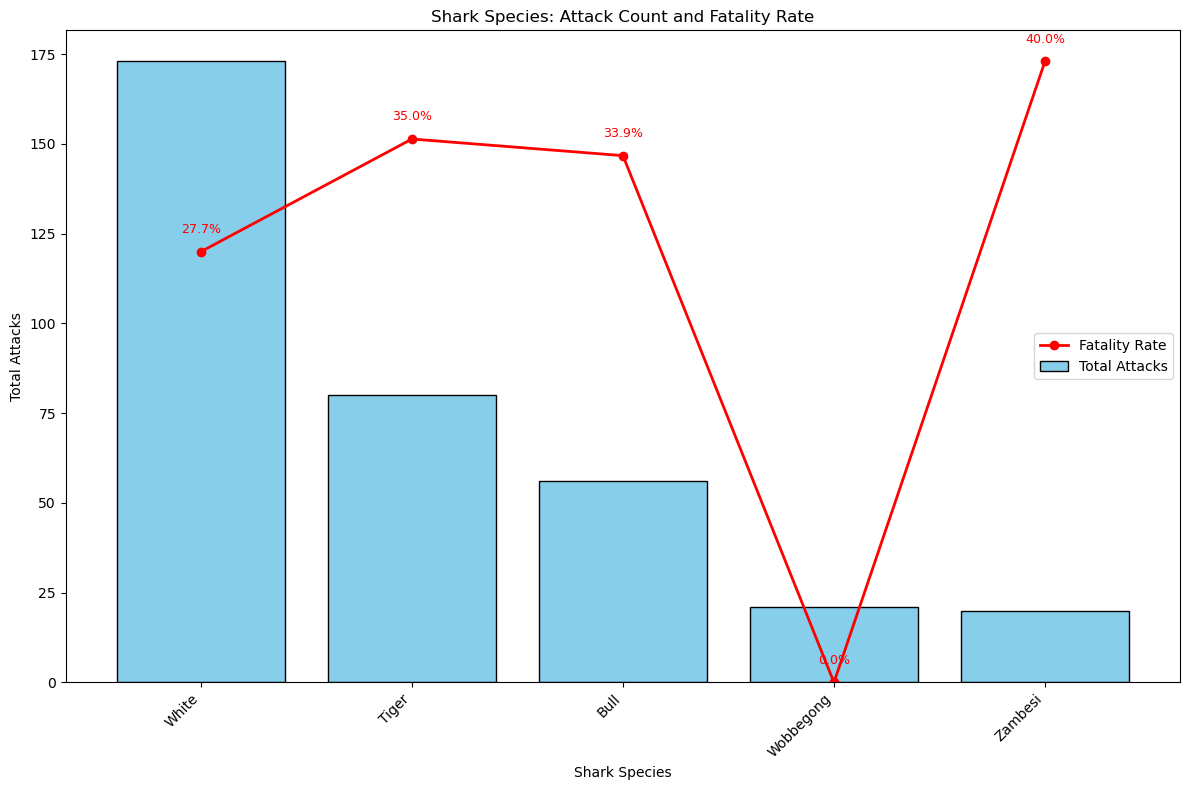

In [41]:

# draw the chart
fig, ax = plt.subplots(figsize=(12, 8))

ax.bar(species_stats['Species'], species_stats['total_attacks'], color='skyblue', edgecolor='black', label='Total Attacks')

max_attacks = species_stats['total_attacks'].max()
max_rate = species_stats['fatality_rate'].max()
scale = max_attacks / max_rate

scaled_rate = []
for rate in species_stats['fatality_rate']:
    scaled_rate.append(rate * scale)

ax.plot(species_stats['Species'], scaled_rate, color='red', marker='o', linewidth=2, label='Fatality Rate')

# add percentage labels
for i in range(len(species_stats)):
    x = species_stats['Species'].iloc[i]
    y = scaled_rate[i]
    label = str(round(species_stats['fatality_rate'].iloc[i], 1)) + '%'
    ax.text(x, y + max_attacks * 0.03, label, ha='center', fontsize=9, color='red')

ax.set_xlabel('Shark Species')
ax.set_ylabel('Total Attacks')
ax.set_title('Shark Species: Attack Count and Fatality Rate')
ax.legend()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**3. Description of the plot**

This dual-axis plot presents two key metrics for shark species that have been identified in at least 20 attacks. The gray bars represent the total number of attacks attributed to each species. The red line with circles shows the fatality rate (percentage of those attacks that were fatal).

**Interpretation of the plot**

The plot immediately identifies the **White Shark** as the most dangerous overall. It has the highest percentage of total attacks (40.0%) and a high fatality rate (27.7%).

The **Tiger Shark** also attacks frequently (17.3% of total attacks) with a very high fatality rate (35.0%), making it extremely dangerous as well.

The **Zambezi Shark** stands out for having the highest fatality rate (40.0%), but it accounts for only 5.4% of total attacks.

The **Bull Shark** has a high fatality rate (33.9%) and accounts for 11.6% of attacks.

In contrast, the **Wobbegong** shark is involved in 5.8% of attacks, but has a very low fatality rate (1.0%), meaning its bites are rarely lethal.

**4. Answer**

The **White Shark** is the most dangerous species overall, combining high attack frequency with high lethality. The **Zambezi Shark** has the highest fatality rate but attacks less often. Danger comes from both how often a species attacks and how deadly those attacks are.